SURSA 1: Termic USGS Landsat 9 Level 2, Collection 2


In [10]:
# 1. Instalăm pachetul geemap (doar dacă nu este deja instalat)
!pip install geemap -q

import ee
import geemap

# 2. Autentificarea și inițializarea Earth Engine
# La prima rulare, îți va cere să dai click pe un link pentru a permite accesul contului tău
ee.Authenticate()
ee.Initialize(project='mede-511511')

# 3. Creăm harta interactivă centrată pe București
Map = geemap.Map(center=[44.43, 26.10], zoom=11, basemap='HYBRID')

# 4. Definim coordonatele pentru filtru (București)
roi = ee.Geometry.Point([26.10, 44.43])

# 5. Apelăm și filtrăm colecția Landsat 9
dataset = (ee.ImageCollection("LANDSAT/LC09/C02/T1_L2")
    .filterBounds(roi)
    .filterDate('2026-06-01', '2026-08-31')
    .sort('CLOUD_COVER')
    .first())

# 6. Extragem banda termică și o transformăm în grade Celsius
thermal_band = dataset.select('ST_B10')
thermal_celsius = thermal_band.multiply(0.00341802).add(149.0).subtract(273.15)

# 7. Definim parametrii de vizualizare și adăugăm stratul pe hartă (cu opacitate 55%)
vis_params = {
    'min': 25,
    'max': 45,
    'palette': ['blue', 'yellow', 'red']
}

Map.addLayer(thermal_celsius, vis_params, 'Temperatura Landsat 9 (Celsius)', True, 0.55)

# 8. Afișăm harta în notebook
Map

Map(center=[44.43, 26.1], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright',…

In [12]:
# 1. Definim un punct de interes (ex. o coordonată centrală din oraș)
punct = ee.Geometry.Point([26.10, 44.43])

# 2. Extragem valoarea pixelului la acea locație (la rezoluția de 30m)
valori = thermal_celsius.reduceRegion(
    reducer=ee.Reducer.first(),
    geometry=punct,
    scale=30
).getInfo() # getInfo() aduce datele din cloud în Colab ca text

# 3. Printăm rezultatul exact
temp = valori.get('ST_B10')
if temp:
    print(f"Temperatura exactă la coordonatele alese este: {temp:.2f} °C")
else:
    print("Nu există date pentru acest punct.")

Temperatura exactă la coordonatele alese este: 45.99 °C


SURSA 2: S2 GEE

In [11]:
# 1. Creăm o nouă hartă pentru Sentinel-2
Map_S2 = geemap.Map(center=[44.43, 26.10], zoom=11, basemap='HYBRID')
roi = ee.Geometry.Point([26.10, 44.43])

# 2. Apelăm și filtrăm colecția Sentinel-2 Level-2A (Optic)
s2_dataset = (ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
    .filterBounds(roi)
    .filterDate('2026-06-01', '2026-08-31')
    .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 10)) # Căutăm imagini cu sub 10% nori
    .first())

# 3. Definim parametrii de vizualizare pentru Optic (Benzile Roșu, Verde, Albastru)
s2_vis_params = {
    'bands': ['B4', 'B3', 'B2'],
    'min': 0,
    'max': 3000
}

# 4. Afișăm imaginea pe hartă
Map_S2.addLayer(s2_dataset, s2_vis_params, 'Sentinel-2 (Optic)')
Map_S2

Map(center=[44.43, 26.1], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright',…

SURSA 3 OMS

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 104.7/104.7 kB 2.9 MB/s eta 0:00:00
Se descarcă drumurile...
Se descarcă parcurile...
Se descarcă clădirile...
Se generează harta...


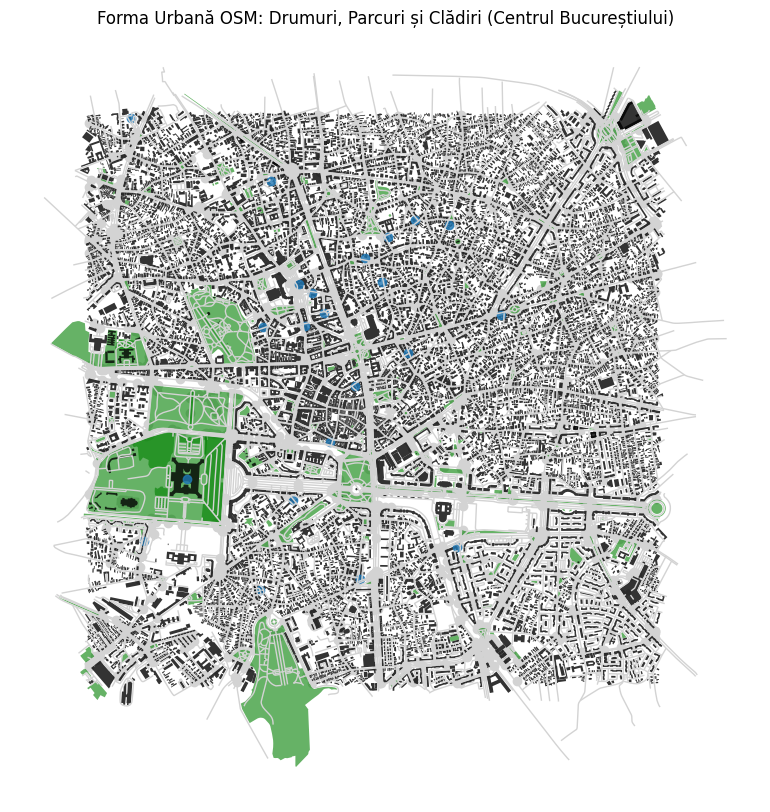

In [13]:
# Instalăm biblioteca necesară
!pip install osmnx -q
import osmnx as ox
import matplotlib.pyplot as plt

# Definim punctul central (Universitate, București) și o rază de 2000 de metri
punct_central = (44.4325, 26.1039)
raza = 2000

print("Se descarcă drumurile...")
tags_drumuri = {"highway": True}
drumuri = ox.features_from_point(punct_central, tags_drumuri, dist=raza)

print("Se descarcă parcurile...")
tags_parcuri = {"leisure": "park", "landuse": ["recreation_ground", "grass", "forest"]}
parcuri = ox.features_from_point(punct_central, tags_parcuri, dist=raza)

print("Se descarcă clădirile...")
tags_cladiri = {"building": True}
cladiri = ox.features_from_point(punct_central, tags_cladiri, dist=raza)

print("Se generează harta...")
# Creăm graficul
fig, ax = plt.subplots(figsize=(10, 10))

# Adăugăm pe rând straturile pe hartă
# 1. Drumurile (linii gri)
drumuri.plot(ax=ax, color='lightgray', linewidth=1)

# 2. Parcurile (poligoane verzi)
parcuri.plot(ax=ax, facecolor='green', alpha=0.6)

# 3. Clădirile (poligoane negre)
cladiri.plot(ax=ax, facecolor='black', alpha=0.8)

# Setăm titlul și ascundem coordonatele de pe margini
plt.title('Forma Urbană OSM: Drumuri, Parcuri și Clădiri (Centrul Bucureștiului)')
plt.axis('off')
plt.show()

GHSL (înălțime, built-up)

In [20]:
# 1. Instalăm o bibliotecă pentru hărți interactive dacă nu este deja (geemap)
!pip install geemap -q

# 2. Importăm bibliotecile
import ee
import geemap

# 3. Autentificarea la serverele Google Earth Engine
ee.Authenticate()
ee.Initialize(project='mede-511511')

print("Autentificare GEE reușită!")

# 4. Definim coordonatele pentru București
bucuresti_punct = ee.Geometry.Point([26.1039, 44.4325]) # Longitudine, Latitudine

# 5. Apelăm setul de date oficial GHSL (Cea mai recentă epocă disponibilă pentru înălțime este 2018)
ghsl_height = ee.Image("JRC/GHSL/P2023A/GHS_BUILT_H/2018").select('built_height')

# 6. Creăm parametrii vizuali
viz_params = {
  'min': 0.0,
  'max': 25.0, # setăm maximul la 25 metri (aprox. 8 etaje)
  'palette': ['000000', '0d0887', '7e03a8', 'cc4778', 'f89540', 'f0f921']
}

# 7. Creăm harta și o centrăm pe București
harta_ghsl = geemap.Map()
harta_ghsl.centerObject(bucuresti_punct, 12)

# 8. Adăugăm stratul de înălțime pe hartă
harta_ghsl.addLayer(ghsl_height, viz_params, 'GHSL Înălțime Clădiri (Cea mai recentă)')

# 9. Afișăm harta direct în Colab
harta_ghsl

Autentificare GEE reușită!


Map(center=[44.4325, 26.103900000000003], controls=(WidgetControl(options=['position', 'transparent_bg'], posi…